# RNN: dự báo chuỗi thời gian (nhiệt độ ngày mai)

**Thế mạnh của RNN:** đơn giản, rất nhẹ và nhanh. Với chuỗi **ngắn** mà thông tin quan trọng nằm ở vài bước gần nhất, RNN thuần đã đủ tốt, không cần kiến trúc phức tạp hơn.

**Cơ chế:** ở mỗi bước thời gian, RNN trộn đầu vào hiện tại với "bộ nhớ" của bước trước:

`h_t = tanh(W·x_t + U·h_(t-1) + b)`

Cùng một bộ trọng số được dùng cho mọi bước, nên mạng xử lý được chuỗi dài bất kỳ. `h_t` là bộ nhớ mang thông tin từ các bước trước.

**Bài toán:** nhìn 30 ngày nhiệt độ thấp nhất gần nhất ở Melbourne (1981 đến 1990, 3.650 ngày), dự đoán nhiệt độ ngày mai. Dự báo thời tiết ngày mai chủ yếu phụ thuộc vài ngày gần nhất, đúng sở trường của RNN.

In [1]:
import pandas as pd
import common as C
C.set_seed(0)
print(C.DEVICE)

cuda


## 1. Dữ liệu
Chia **theo thời gian** 70/15/15 (không xáo trộn) để mô hình không nhìn thấy tương lai khi học. Chuẩn hóa chỉ dùng thống kê của tập train.

{'train': 2525, 'val': 547, 'test': 548} (số mẫu; mỗi mẫu = 30 ngày vào, 1 ngày ra)


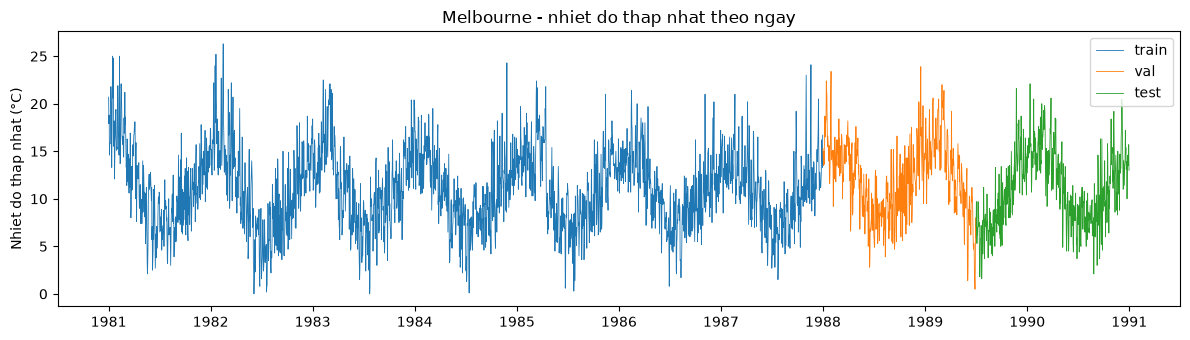

In [2]:
loaders, info = C.load_temperature(window=30, batch_size=64)
print({k: len(v.dataset) for k, v in loaders.items()}, '(số mẫu; mỗi mẫu = 30 ngày vào, 1 ngày ra)')
C.plot_temperature(info)

### Hai mô hình "không học" làm mốc so sánh
Nếu RNN không thắng được hai mốc này thì nó chưa học được gì hữu ích.
- **Persistence**: ngày mai = hôm nay.
- **Trung bình 7 ngày**: ngày mai = trung bình 7 ngày gần nhất.

In [3]:
base = C.baselines(info)
pd.DataFrame(base).T.round(3)

,MAE,RMSE
persistence (hom qua),2.036,2.572
trung binh 7 ngay,1.968,2.540


## 2. Mô hình RNN
2 lớp RNN (tanh), 64 đơn vị ẩn. Lấy trạng thái ẩn ở bước cuối (đã "đọc" hết 30 ngày) rồi qua một lớp Linear ra 1 số.

In [4]:
rnn = C.SeqRegressor('rnn', hidden=64, layers=2)
print(rnn)
print(f'{C.n_params(rnn):.3f}M tham số')

SeqRegressor(
  (rnn): RNN(1, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
0.013M tham số


## 3. Huấn luyện
Loss MSE, AdamW, cắt gradient (`clip_grad_norm`) để chống bùng nổ gradient, giảm learning rate khi val không cải thiện, chọn checkpoint theo val loss.

ep 01/40 | train mse 0.4721 | val mse 0.3600


ep 05/40 | train mse 0.3762 | val mse 0.3360


ep 10/40 | train mse 0.3870 | val mse 0.3418


ep 15/40 | train mse 0.3739 | val mse 0.3288


ep 20/40 | train mse 0.3615 | val mse 0.3304


ep 25/40 | train mse 0.3587 | val mse 0.3280


ep 30/40 | train mse 0.3576 | val mse 0.3278


ep 35/40 | train mse 0.3540 | val mse 0.3229


ep 40/40 | train mse 0.3532 | val mse 0.3239


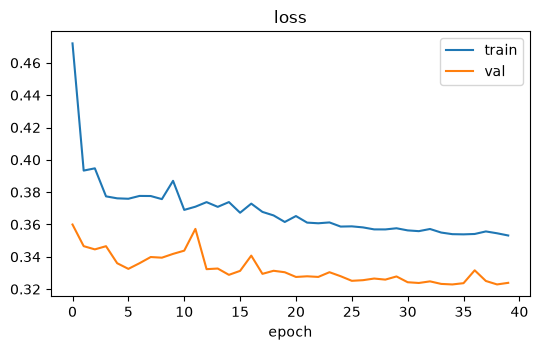

In [5]:
rnn, h_rnn, t_rnn = C.train_regressor('rnn_temp', rnn, loaders, epochs=40, lr=3e-3)
C.plot_history(h_rnn)

## 4. Đánh giá trên tập test
MAE và RMSE tính bằng độ C (sau khi bỏ chuẩn hóa). Để thấy RNN "đủ dùng" ở chuỗi ngắn, huấn luyện thêm LSTM cùng cấu hình để so sánh.

In [6]:
res_rnn, p_rnn, true = C.evaluate_regressor('rnn_temp', rnn, loaders, info, h_rnn, t_rnn)

C.set_seed(0)
lstm = C.SeqRegressor('lstm', hidden=64, layers=2)
lstm, h_lstm, t_lstm = C.train_regressor('lstm_temp', lstm, loaders, epochs=40, lr=3e-3, verbose=False)
res_lstm, p_lstm, _ = C.evaluate_regressor('lstm_temp', lstm, loaders, info, h_lstm, t_lstm)

[rnn_temp] test MAE 1.730 °C | RMSE 2.209 °C


[lstm_temp] test MAE 1.714 °C | RMSE 2.194 °C


In [7]:
rows = {**base,
        'RNN': {'MAE': res_rnn['MAE'], 'RMSE': res_rnn['RMSE']},
        'LSTM': {'MAE': res_lstm['MAE'], 'RMSE': res_lstm['RMSE']}}
df = pd.DataFrame(rows).T
df['tham số (M)'] = [None, None, res_rnn['params_M'], res_lstm['params_M']]
df['thời gian train (s)'] = [None, None, t_rnn, t_lstm]
df.round(3)

,MAE,RMSE,tham số (M),thời gian train (s)
persistence (hom qua),2.036,2.572,NaN,NaN
trung binh 7 ngay,1.968,2.540,NaN,NaN
RNN,1.730,2.209,0.013,3.682
LSTM,1.714,2.194,0.050,3.896


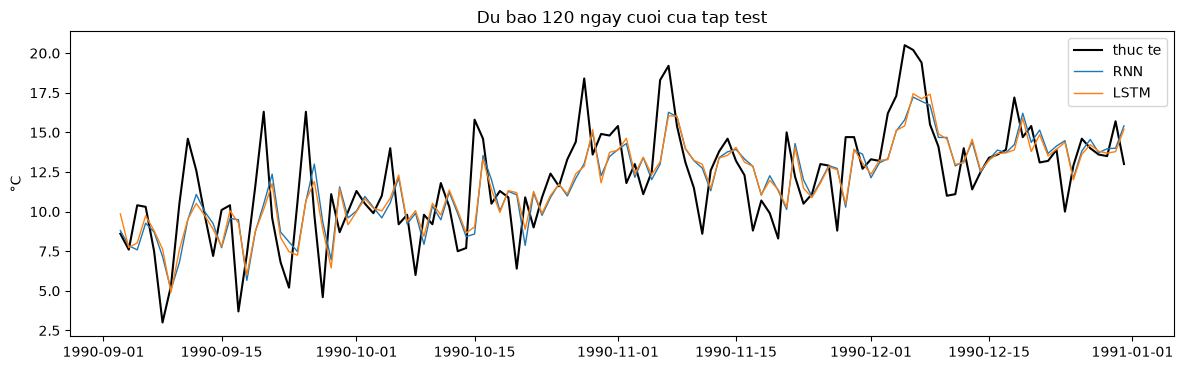

In [8]:
C.plot_forecast(info, {'RNN': p_rnn, 'LSTM': p_lstm}, last=120)

## 5. Nhận xét

**Kết quả trên tập test (548 ngày), sai số tính bằng °C:**

| Mô hình | MAE | RMSE | Tham số | Thời gian train |
|---|---|---|---|---|
| Persistence (ngày mai = hôm nay) | 2,036 | 2,572 | không có | không có |
| Trung bình 7 ngày | 1,968 | 2,540 | không có | không có |
| **RNN** | **1,730** | **2,209** | 0,0127M | 3,7 s |
| LSTM | 1,714 | 2,194 | 0,0505M | 3,9 s |

**RNN học được điều hữu ích:** MAE giảm khoảng 15% so với persistence (2,036 xuống 1,730) và RMSE giảm khoảng 14%. Mô hình chỉ có 12,7 nghìn tham số và train xong trong khoảng 4 giây.

**RNN đủ dùng ở chuỗi ngắn:** LSTM chỉ nhỉnh hơn RNN 0,015 °C MAE, dù có số tham số gấp khoảng 4 lần. Mức chênh này quá nhỏ so với dao động giữa các lần chạy, nên với một lần chạy trên 548 ngày test, **không thể kết luận LSTM tốt hơn**. Điều này phù hợp với nhận định ban đầu: nhiệt độ ngày mai chủ yếu phụ thuộc vài ngày gần nhất, không cần "bộ nhớ dài" của LSTM.

**Giới hạn:** sai số còn khoảng 1,7 °C vì thời tiết có độ ngẫu nhiên tự nhiên mà chuỗi nhiệt độ một biến không giải thích được. Thêm các biến khác (độ ẩm, áp suất) sẽ cần thiết để giảm tiếp. Kết quả là một lần chạy với một seed.

**Kết luận:** với chuỗi ngắn và phụ thuộc gần, RNN thuần là lựa chọn gọn nhẹ, nhanh và hiệu quả, không cần kiến trúc phức tạp hơn.